In [1]:
#import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

# Fixed as-of reporting date (kept constant so tenure/age are reproducible)
REPORT_DATE = pd.Timestamp('2025-04-01')

In [2]:
#import database
conn =sqlite3.connect('customer_churn.db')
sql_query="""
SELECT name
FROM sqlite_master
WHERE type='table'
"""
tables =pd.read_sql(sql_query,conn)

# create dataframe for each table

for table_name in tables['name']:
    df=pd.read_sql(f"SELECT *from  {table_name}",conn)
    globals()[f"df_{table_name}"]=df
    print(f"Created dataframe :df_{table_name}")
    
conn.close()

Created dataframe :df_db_customer
Created dataframe :df_db_subscription
Created dataframe :df_db_support


In [3]:
conn=sqlite3.connect('customer_churn.db')

for table_name in tables['name']:
    print (f"\nTable Name :{table_name}")
    #get column information
    columns_query=f"PRAGMA table_info({table_name});"
    columns=pd.read_sql(columns_query,conn)
    print("columns:")
    print(columns['name'].tolist())

conn.close()


Table Name :db_customer
columns:
['customerid', 'name', 'country', 'state', 'gender', 'dob', 'interests', 'pincode']

Table Name :db_subscription
columns:
['customerid', 'subscription_start_date', 'subscription_type', 'renewal_date', 'plan_type', 'contract_type', 'cancellation_date', 'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score']

Table Name :db_support
columns:
['customerid', 'complaint_date', 'escalations', 'csat_score', 'col_1', 'comment']


In [4]:
#data cleaning


In [5]:
#df_db_customer.head()
df_db_customer.tail()

,customerid,name,country,state,gender,dob,interests,pincode
16,0020-JDNXP,rikim,India,Meghalaya,Female,1994-08-19 00:00:00,NaN,None
17,0021-IKXGC,vishakha,India,Rajasthan,Female,2000-09-02 00:00:00,NaN,None
18,0022-TCJCI,raghvendra,India,Telangana,Male,1983-12-30 00:00:00,NaN,None
19,0023-HGHWL,rishabh,India,Uttar Pradesh,Men,1991-05-14 00:00:00,NaN,None
20,0023-UYUPN,sudevi,India,Maharashtra,Women,1977-10-06 00:00:00,NaN,None


In [6]:
df_db_customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   customerid  21 non-null     str   
 1   name        21 non-null     str   
 2   country     18 non-null     str   
 3   state       21 non-null     str   
 4   gender      21 non-null     str   
 5   dob         21 non-null     str   
 6   interests   4 non-null      str   
 7   pincode     0 non-null      object
dtypes: object(1), str(7)
memory usage: 1.4+ KB


In [7]:
#rename col-name
#drop columns-interest and pincode
#change data type- dob
#data standardization -gender
#fix missing value

In [8]:
#rename col-name
df_db_customer.rename(columns={'name':'customer_name'},inplace=True)
df_db_customer

,customerid,customer_name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00,travel,None
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00,NaN,None
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00,movie,None
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00,NaN,None
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00,drama,None
5,0013-MHZWF,durga,NaN,Delhi,Women,1988-12-10 00:00:00,NaN,None
6,0013-SMEOE,mina,India,Meghalaya,Female,1976-09-21 00:00:00,NaN,None
7,0014-BMAQU,madan,India,Rajasthan,Male,1999-03-14 00:00:00,NaN,None
8,0015-UOCOJ,maya,NaN,Kathmandu,Women,1985-07-07 00:00:00,NaN,None
9,0016-QLJIS,arjun,Nepal,Kathmandu,Male,1993-10-29 00:00:00,NaN,None


In [9]:
#drop columns-interest and pincode

#df_db_customer.drop(df_db_customer.columns[-2:],axis=1)

df_db_customer.drop(columns=['interests' ,'pincode'],inplace=True) 

In [10]:
df_db_customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   customerid     21 non-null     str  
 1   customer_name  21 non-null     str  
 2   country        18 non-null     str  
 3   state          21 non-null     str  
 4   gender         21 non-null     str  
 5   dob            21 non-null     str  
dtypes: str(6)
memory usage: 1.1 KB


In [11]:
#change data type- dob
df_db_customer['dob']=pd.to_datetime(df_db_customer['dob'])

In [12]:
#data standardization -gender

#df_db_customer['gender'].unique()

df_db_customer['gender']=df_db_customer['gender'].replace({'Men':'Male','Women':'Female'})

In [13]:
#fix missing value

df_db_customer[df_db_customer['country'].isna()]

,customerid,customer_name,country,state,gender,dob
5,0013-MHZWF,durga,NaN,Delhi,Female,1988-12-10
8,0015-UOCOJ,maya,NaN,Kathmandu,Female,1985-07-07
12,0018-NYROU,chitra,NaN,Telangana,Female,2004-12-01


In [14]:
df_db_customer[['country','state']]

,country,state
0,India,Maharashtra
1,India,Karnataka
2,India,Delhi
3,India,Nagaland
4,India,Delhi
5,NaN,Delhi
6,India,Meghalaya
7,India,Rajasthan
8,NaN,Kathmandu
9,Nepal,Kathmandu


In [15]:
#country and state -unique value pair

state_country_mapping = df_db_customer.dropna(subset=['country']).set_index('state')['country'].to_dict()

df_db_customer['country']=df_db_customer['country'].fillna(df_db_customer['state'].map(state_country_mapping))

In [16]:
df_db_customer[df_db_customer['country'].isna()]

,customerid,customer_name,country,state,gender,dob


In [17]:
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaN,NaN,13.99,627,12
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaN,NaN,6.99,210,34
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaN,NaN,22.99,1725,8
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88


In [18]:
df_db_subscription.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customerid               21 non-null     str    
 1   subscription_start_date  21 non-null     str    
 2   subscription_type        21 non-null     str    
 3   renewal_date             21 non-null     str    
 4   plan_type                21 non-null     str    
 5   contract_type            21 non-null     str    
 6   cancellation_date        6 non-null      str    
 7   cancellation_reason      6 non-null      str    
 8   monthly_charges          21 non-null     float64
 9   cltv                     21 non-null     int64  
 10  churn_score              21 non-null     int64  
dtypes: float64(1), int64(2), str(8)
memory usage: 1.9 KB


In [19]:
date_col=['subscription_start_date' ,'renewal_date','cancellation_date']
df_db_subscription[date_col]= df_db_subscription[date_col].apply(pd.to_datetime)
# df_db_subscription.info()

In [20]:
_

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaN,NaN,13.99,627,12
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaN,NaN,6.99,210,34
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaN,NaN,22.99,1725,8
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88


In [21]:
df_db_support.head()

,customerid,complaint_date,escalations,csat_score,col_1,comment
0,0003-MKNFE,2024-08-28 00:00:00,N,60,None,service issue
1,0003-MKNFE,2024-08-28 00:00:00,Y,10,None,demaned refund
2,0013-EXCHZ,2024-01-20 00:00:00,Y,20,None,NaN
3,0013-MHZWF,2025-03-18 00:00:00,N,90,None,guidance to renew
4,0013-SMEOE,2024-11-01 00:00:00,N,30,None,NaN


In [22]:
df_db_support.drop(columns=['col_1','comment'],inplace=True)

In [23]:
df_db_support['complaint_date']=pd.to_datetime(df_db_support['complaint_date'])

In [24]:
df_db_support.info()

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   customerid      9 non-null      str           
 1   complaint_date  9 non-null      datetime64[us]
 2   escalations     9 non-null      str           
 3   csat_score      9 non-null      int64         
dtypes: datetime64[us](1), int64(1), str(2)
memory usage: 420.0 bytes


In [25]:
#Feature engineering and data analysis

In [26]:
#create churn_flag using existing col
df_db_subscription['churn_flag']= np.where(df_db_subscription['cancellation_date'].notna(),1,0)

In [27]:
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,12,0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,34,0
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,NaN,22.99,1725,8,0
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88,1


In [28]:
df_db_support.head()

,customerid,complaint_date,escalations,csat_score
0,0003-MKNFE,2024-08-28,N,60
1,0003-MKNFE,2024-08-28,Y,10
2,0013-EXCHZ,2024-01-20,Y,20
3,0013-MHZWF,2025-03-18,N,90
4,0013-SMEOE,2024-11-01,N,30


In [29]:
df_db_support['complaint_count']=df_db_support.groupby('customerid')['customerid'].transform('count')

In [30]:
df_db_support=df_db_support.sort_values('complaint_date').drop_duplicates('customerid',keep='last')

In [31]:
df_db_support['customerid'].size

7

In [32]:
#first fix support table and then merge
df=(df_db_subscription
       .merge(df_db_customer,on='customerid',how='left')
       .merge(df_db_support,on='customerid',how='left'))

In [33]:
df.shape

(21, 21)

In [34]:
df.to_csv('exported_churn_data.csv',index=False)

In [35]:
#data Analysis

In [36]:
#1. Churn rate

In [37]:
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count'],
      dtype='str')

In [38]:
churn_rate=df['churn_flag'].mean()*100
print("Churn Rate =",round(churn_rate,2),"%")

Churn Rate = 28.57 %


In [39]:
# 2. Retention Rate
retention_rate= 100-churn_rate
print("Retention Rate =",round(retention_rate,2),"%")

Retention Rate = 71.43 %


In [40]:
df.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,churn_flag,customer_name,country,state,gender,dob,complaint_date,escalations,csat_score,complaint_count
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,...,0,keshav,India,Maharashtra,Male,1982-04-12,NaT,NaN,NaN,NaN
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,1,raghav,India,Karnataka,Male,1995-11-23,2024-08-28,Y,10.0,2.0
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,...,0,lalita,India,Delhi,Female,1978-02-15,NaT,NaN,NaN,NaN
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,NaN,22.99,1725,...,0,mohan,India,Nagaland,Male,2001-08-30,NaT,NaN,NaN,NaN
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,...,1,mira,India,Delhi,Female,1990-05-05,2024-01-20,Y,20.0,1.0


In [41]:
# 3. churn by plan type

churn_by_plan=df.groupby('plan_type')['churn_flag'].mean().mul(100).round(2).reset_index(name='churn_rate_pct')
print(churn_by_plan)

  plan_type  churn_rate_pct
0     Basic           60.00
1   Premium           14.29
2  Standard           22.22


In [42]:
# 4 a. churn by state +sum(revenue)&count of users

churn_by_state=df.groupby('state').agg(
    churn_rate_pct= ('churn_flag',lambda x:round(x.mean()*100,2)),
    revenue=('monthly_charges','sum'),
    user_count=('state','count')
).reset_index()
print(churn_by_state)



           state  churn_rate_pct  revenue  user_count
0          Delhi           25.00    52.96           4
1      Karnataka          100.00    20.98           2
2      Kathmandu            0.00    20.98           2
3    Maharashtra            0.00    50.97           3
4      Meghalaya           66.67    42.97           3
5       Nagaland            0.00    22.99           1
6      Rajasthan            0.00    36.98           2
7      Telangana           50.00    30.98           2
8  Uttar Pradesh            0.00   115.98           2


In [43]:
# 4 b. churn by subscription type

churn_by_subscription_type=df.groupby('subscription_type')['churn_flag'].mean().mul(100).round(2).reset_index(name='churn_rate_pct')
print(churn_by_subscription_type)

  subscription_type  churn_rate_pct
0           Organic            0.00
1              Paid           16.67
2          Refferal           83.33


In [44]:
#5. ARPU- Avg Revenue per user
arpu=df['monthly_charges'].mean()
print('ARPU =',round(arpu,2))


ARPU = 18.85


In [45]:
#6. Avg Customer Tenure
#count of days users has used our service:cancellation date else reporting date

today=REPORT_DATE

df['tenure_days']=np.where(
     df['cancellation_date'].notna(),

     (df['cancellation_date']-df['subscription_start_date']).dt.days,
     (today-df['subscription_start_date']).dt.days,
 )
avg_tenure=df['tenure_days'].mean()
print("Avg Tenure (Days)=",round(avg_tenure))
     

Avg Tenure (Days)= 1159


In [46]:
# customer age

today=REPORT_DATE
df['customer_age']=(today-df['dob']).dt.days / 365.25

avg_age=df['customer_age'].mean()
print("Avg age (Years)=",round(avg_age))

Avg age (Years)= 36


In [47]:
#revenue at risk-revenue lost from churned users (monthly charges)
revenue_at_risk=df.loc[df['churn_flag']==1,'monthly_charges'].sum()
print("Revenue at Risk (monthly) =",round(revenue_at_risk,2))

Revenue at Risk (monthly) = 73.94


In [48]:
#8. Escalation rate
escalation_rate=(df['escalations']=='Y').mean()*100
print("Escalation Rate =",round(escalation_rate,2),"%")

Escalation Rate = 19.05 %


In [49]:
#9. Avg Complaint per user
avg_complaints=df['complaint_count'].sum()/df['customerid'].nunique()
print("Avg Complaint per user =",round(avg_complaints,2))

Avg Complaint per user = 0.43


In [50]:
#correlation Escalation vs churn
df['escalation_flag']=np.where(df['escalations']=='Y',1,0)

corr_df=df[['escalation_flag','churn_flag']].dropna()
correlation = corr_df['escalation_flag'].corr(corr_df['churn_flag'])
print("Correlation between escalation vs churn is =" , round(correlation,2))

Correlation between escalation vs churn is = 0.77


In [51]:
# 11. churn risk- create a column using existing col

conditions=[
    (df['churn_score']<50),
    (df['churn_score']>=50)&(df['churn_score']<70),
    (df['churn_score']>=70)
]
choices=['low','med','high']
df['churn_risk']=np.select(conditions,choices,default='unknown')

In [52]:
df[['churn_risk','churn_score']].head()

,churn_risk,churn_score
0,low,12
1,high,91
2,low,34
3,low,8
4,high,88


In [53]:
# visualization using matplotlib

In [54]:
df_visual =df.copy()

In [55]:
df_visual.shape

(21, 25)

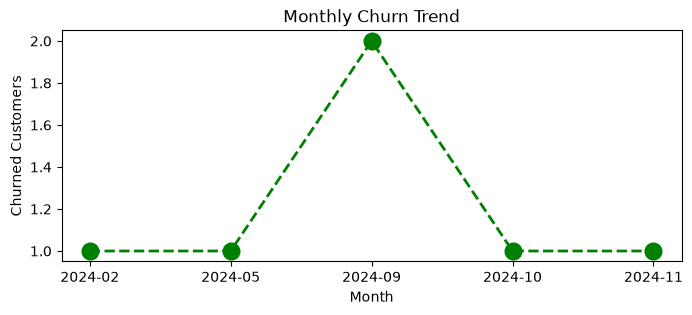

In [56]:
#Monthly churn trend

df_visual['cancellation_month']=df_visual['cancellation_date'].dt.to_period('M')
churn_trend =df_visual[df_visual['churn_flag']==1].groupby('cancellation_month').size()

plt.figure(figsize=(8,3))
plt.plot(churn_trend.index.astype(str),churn_trend.values, color='green',marker='o', linestyle='dashed',linewidth=2,markersize=12)
plt.title('Monthly Churn Trend')
plt.xlabel('Month')
plt.ylabel('Churned Customers')
plt.show()

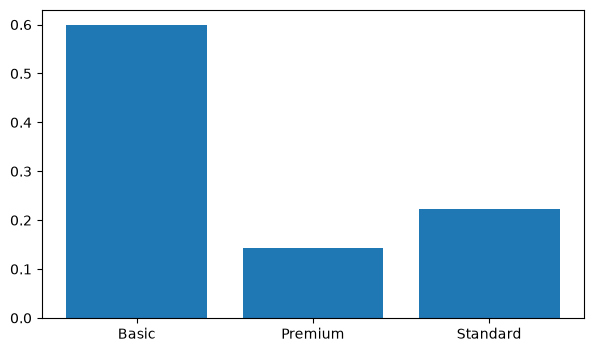

In [57]:
#churn by plan type

churn_plan=df_visual.groupby('plan_type')['churn_flag'].mean()                                  
plt.figure(figsize=(7,4))

plt.bar(churn_plan.index,churn_plan.values)
plt.show()


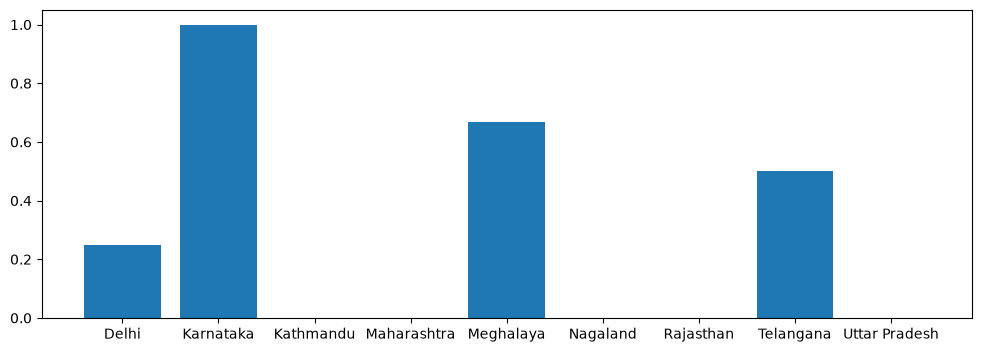

In [58]:
#churn by state

churn_plan=df_visual.groupby('state')['churn_flag'].mean()                                  
plt.figure(figsize=(12,4))

plt.bar(churn_plan.index,churn_plan.values)
plt.show()


In [59]:
df_visual[['plan_type','contract_type','churn_score','churn_flag','churn_risk','escalation_flag']].head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalation_flag
0,Standard,Annual,12,0,low,0
1,Premium,Annual,91,1,high,1
2,Basic,Monthly,34,0,low,0
3,Premium,Annual,8,0,low,0
4,Standard,Monthly,88,1,high,1


In [60]:
# Incorrect method of encoding as numbers are not assigned based on priority

df_encoded=df_visual[['plan_type','contract_type','churn_score','churn_flag','churn_risk','escalation_flag']]

categorial_cols=['plan_type','contract_type','churn_risk']

for col in categorial_cols:
    df_encoded[col]=df_encoded[col].astype('category').cat.codes

In [61]:
df_encoded.head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalation_flag
0,2,0,12,0,1,0
1,1,0,91,1,0,1
2,0,1,34,0,1,0
3,1,0,8,0,1,0
4,2,1,88,1,0,1


<Axes: >

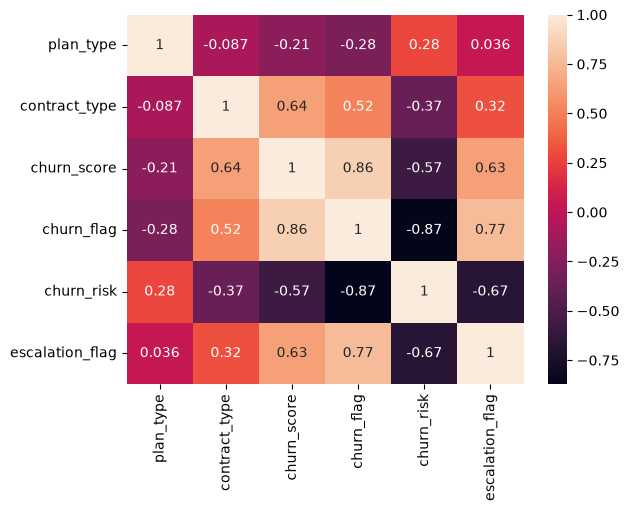

In [62]:
#Heatmap (correlation matrix)
sns.heatmap(df_encoded.corr(),annot=True)

In [63]:
df_visual['churn_risk'].unique()

<StringArray>
['low', 'high', 'med']
Length: 3, dtype: str

In [64]:
#correct method of encoding -based on priority

df_encoded=df_visual[['plan_type','contract_type','churn_score','churn_flag','churn_risk','escalation_flag']]

order_mappings={
    'plan_type':['Basic','Standard','Premium'],
    'contract_type':['Monthly','Annual'],
    'churn_risk':['low','med','high']}

for col,order in order_mappings.items():
    df_encoded[col]=pd.Categorical(df_encoded[col].astype('category'),categories=order,ordered=True).codes

In [65]:
df_encoded.head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalation_flag
0,1,1,12,0,0,0
1,2,1,91,1,2,1
2,0,0,34,0,0,0
3,2,1,8,0,0,0
4,1,0,88,1,2,1


<Axes: >

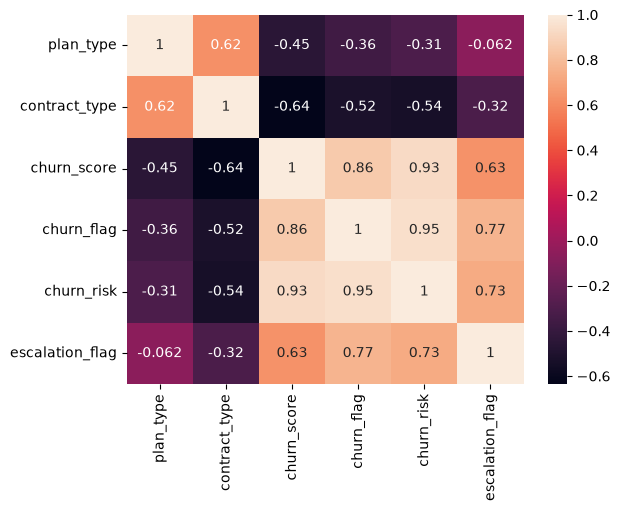

In [66]:
#Heatmap (correlation matrix)
sns.heatmap(df_encoded.corr(),annot=True)

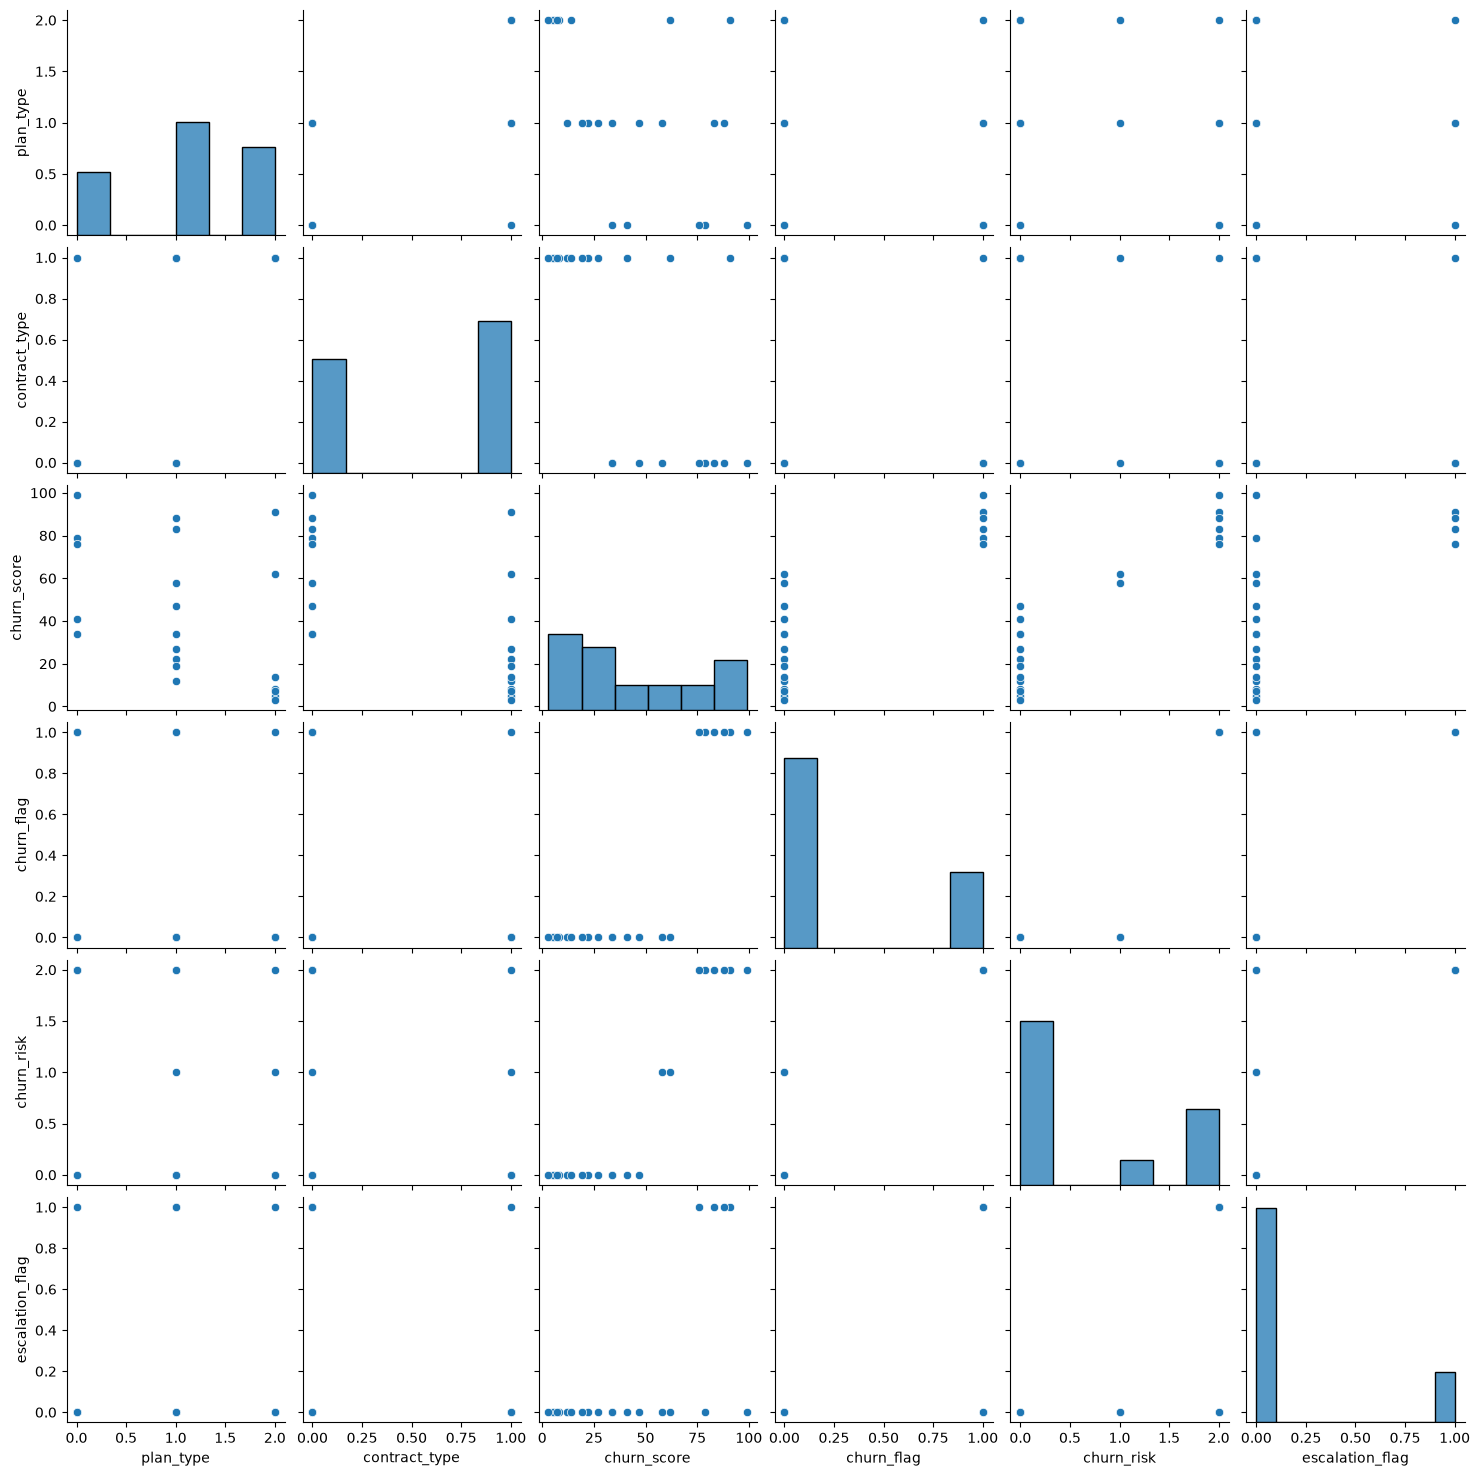

In [67]:
#pair plot

sns.pairplot(df_encoded)

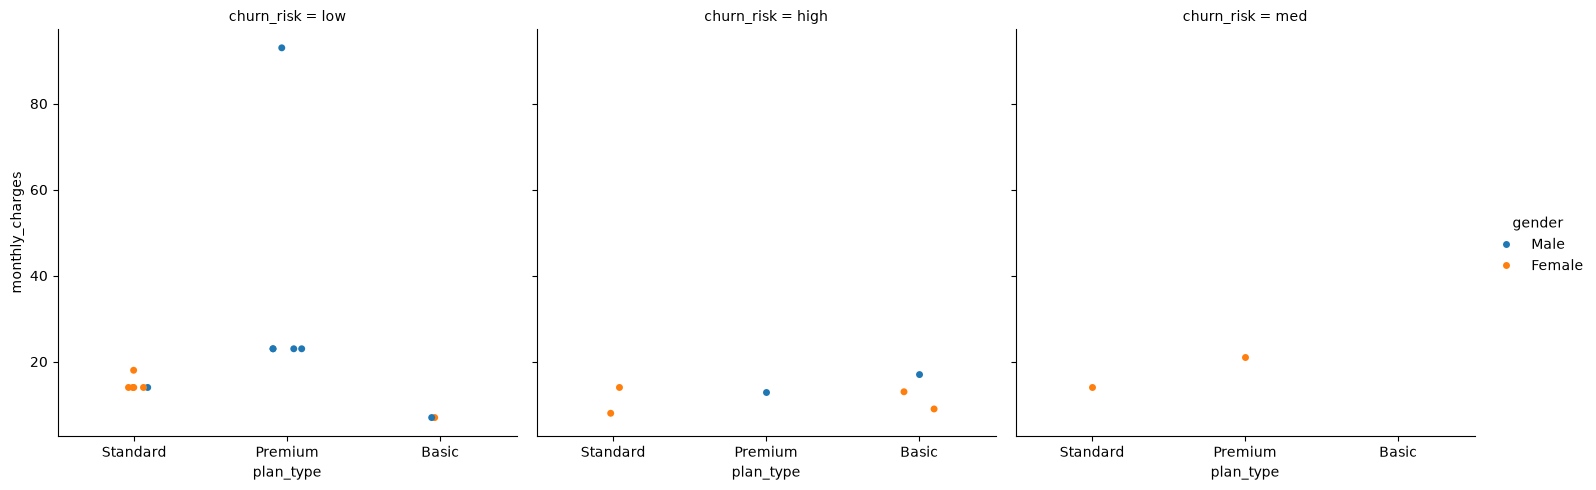

In [68]:
#catplt/facegrid plot- multi-dim comparison

sns.catplot(data=df_visual,
            x='plan_type',
            y='monthly_charges',
            hue='gender',
            col='churn_risk')